#### 1. Тема та мета роботи.
##### Тема:
Аналіз продуктивності алгоритмів.
##### Мета:
Набути практичних навичок аналізу складності алгоритмів, експериментального дослідження їх продуктивності, профілювання програмного коду та оцінювання впливу розміру вхідних даних на часові й просторові характеристики програмних систем.

#### 2. Постановка задачі.
Для однієї обчислювальної задачі (Варіант 8. Перевірка належності елемента множині (Лінійний пошук, Hash Set)) необхідно реалізувати два алгоритми
розв'язання, які відрізняються підходом або алгоритмічною складністю, провести
експериментальне дослідження їх продуктивності та виконати порівняльний аналіз.

#### 3. Теоретичний аналіз алгоритмів (Варіант 8: Перевірка належності елемента множині - Лінійний пошук, Hash Set).

##### 1. Лінійний пошук
Алгоритм послідовно перевіряє кожен елемент колекції, порівнюючи його з шуканим значенням, поки не знайде збіг або не пройде всі елементи.

**Псевдокод:**
```text
function LinearSearch(array, target):
    for each element in array:
        if element == target:
            return true  // Елемент знайдено
    return false         // Елемент не знайдено
```

**Часова складність:**
- *Найкращий випадок:* $O(1)$ — якщо шуканий елемент знаходиться на першій позиції.
- *Середній випадок:* $O(n)$ — в середньому доводиться перевірити половину елементів.
- *Найгірший випадок:* $O(n)$ — шуканий елемент знаходиться в кінці колекції або взагалі відсутній.

**Просторова складність:**
- $O(1)$ — алгоритм не потребує додаткової пам'яті, незалежно від розміру вхідних даних (використовуються лише змінні для ітерації).

##### 2. Hash Set
Hash Set використовує хеш-функцію для обчислення індексу (хешу), за яким елемент зберігається у внутрішньому масиві. Перевірка належності полягає в обчисленні хешу шуканого елемента і швидкій перевірці відповідної комірки пам'яті. У разі виникнення колізій застосовуються методи їх вирішення.

**Псевдокод:**
```text
function HashSetSearch(hash_set, target):
    index = hash_function(target) % hash_set.capacity
    bucket = hash_set.buckets[index]
    
    for each element in bucket:  // Обробка колізій
        if element == target:
            return true          // Елемент знайдено
            
    return false                 // Елемент не знайдено
```

**Часова складність:**
- *Найкращий випадок:* $O(1)$ — елемент знайдено одразу, колізій немає.
- *Середній випадок:* $O(1)$ — за умови рівномірного розподілу хеш-функції та достатнього розміру внутрішньої таблиці.
- *Найгірший випадок:* $O(n)$ — усі елементи мають однаковий хеш. У такому разі пошук вироджується в лінійний.

**Просторова складність:**
- $O(n)$ — потребує додаткової пам'яті для зберігання самої хеш-таблиці, де $n$ — кількість елементів. Також завжди є резервування порожніх слотів для підтримки швидкодії на рівні $O(1)$.

##### **Порівняльна таблиця**

| Характеристика | Лінійний пошук | Пошук через Hash Set |
| :--- | :--- | :--- |
| **Найкращий випадок** | $O(1)$ | $O(1)$ |
| **Середній випадок** | $O(n)$ | $O(1)$ |
| **Найгірший випадок** | $O(n)$ | $O(n)$ |
| **Просторова складність** | $O(1)$ | $O(n)$ |

#### 4. Лістинг програмного коду. Реалізація алгоритмів.

In [3]:
import cProfile
import pstats
import time
import tracemalloc
import random

def linear_search(arr, target):
    for item in arr:
        if item == target:
            return True
    return False

class HashSet:
    def __init__(self, size):
        self.size = size
        self.buckets = [[] for _ in range(size)]

    def _hash(self, key):
        return hash(key) % self.size

    def insert(self, key):
        index = self._hash(key)
        if key not in self.buckets[index]:
            self.buckets[index].append(key)

    def contains(self, key):
        index = self._hash(key)
        for item in self.buckets[index]:
            if item == key:
                return True
        return False

profiler = cProfile.Profile()
profiler.enable()

sizes = [100, 1000, 5000, 10000, 50000, 100000]
runs = 5

avg_linear_times = []
avg_hash_times = []
linear_mems = []
hash_mems = []

print("Розмір даних | Алгоритм | Середній час (мс) | Середня пам. (МБ) | Макс. пам'ять (МБ)")
print("-" * 85)

for size in sizes:
    data = [random.randint(0, size * 2) for _ in range(size)]
    targets = [random.choice(data) for _ in range(100)]

    linear_times = []
    tracemalloc.start()
    for _ in range(runs):
        start_time = time.perf_counter()
        for t in targets:
            linear_search(data, t)
        linear_times.append((time.perf_counter() - start_time) * 1000)

    current_mem_linear, peak_mem_linear = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    avg_time_linear = sum(linear_times) / runs
    avg_mem_linear_mb = current_mem_linear / (1024 * 1024)
    peak_mem_linear_mb = peak_mem_linear / (1024 * 1024)

    avg_linear_times.append(avg_time_linear)
    linear_mems.append(peak_mem_linear_mb)

    hash_times = []
    tracemalloc.start()

    hash_set = HashSet(size)
    for item in data:
        hash_set.insert(item)

    for _ in range(runs):
        start_time = time.perf_counter()
        for t in targets:
            hash_set.contains(t)
        hash_times.append((time.perf_counter() - start_time) * 1000)

    current_mem_hash, peak_mem_hash = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    avg_time_hash = sum(hash_times) / runs
    avg_mem_hash_mb = current_mem_hash / (1024 * 1024)
    peak_mem_hash_mb = peak_mem_hash / (1024 * 1024)

    avg_hash_times.append(avg_time_hash)
    hash_mems.append(peak_mem_hash_mb)

    print(f"{size:<12} | Лінійний пошук   | {avg_time_linear:<17.4f} | {avg_mem_linear_mb:<17.6f} | {peak_mem_linear_mb:.6f}")
    print(f"{size:<12} | Hash Set         | {avg_time_hash:<17.4f} | {avg_mem_hash_mb:<17.6f} | {peak_mem_hash_mb:.6f}")

profiler.disable()
stats = pstats.Stats(profiler)

Розмір даних | Алгоритм | Середній час (мс) | Середня пам. (МБ) | Макс. пам'ять (МБ)
-------------------------------------------------------------------------------------
100          | Лінійний пошук   | 0.1675            | 0.001380          | 0.001461
100          | Hash Set         | 0.1282            | 0.010600          | 0.010699
1000         | Лінійний пошук   | 0.8675            | 0.000061          | 0.000160
1000         | Hash Set         | 0.1543            | 0.077666          | 0.077785
5000         | Лінійний пошук   | 5.3120            | 0.000061          | 0.000160
5000         | Hash Set         | 0.1678            | 0.399145          | 0.399263
10000        | Лінійний пошук   | 10.4595           | 0.000061          | 0.000160
10000        | Hash Set         | 0.1754            | 0.804947          | 0.805065
50000        | Лінійний пошук   | 41.7499           | 0.000113          | 0.000442
50000        | Hash Set         | 0.1687            | 4.055588          | 4.055687

#### 5. Результати часового експерименту.
| Розмір даних | Лінійний пошук | Hash Set |
| :--- | :--- | :--- |
| **100** | 0.2247 | 0.1311 |
| **1 000** | 1.3193 | 0.1216 |
| **5 000** | 4.2953 | 0.1300 |
| **10 000** | 7.1091 | 0.1977 |
| **50 000** | 46.9604 | 0.1659 |
| **100 000** | 70.1201 | 0.2114 |

#### 6. Аналіз використання пам’яті.
| Розмір вхідних даних (n) | Алгоритм | Середнє використання пам'яті, МБ | Максимальне використання пам'яті, МБ | Теоретична просторова складність |
| :--- | :--- | :--- | :--- | :--- |
| 100 | Лінійний пошук | 0.000465 | 0.000557 | $O(1)$ |
| 100 | Hash Set | 0.009674 | 0.009743 | $O(n)$ |
| 1 000 | Лінійний пошук | 0.000084 | 0.000153 | $O(1)$ |
| 1 000 | Hash Set | 0.080985 | 0.081103 | $O(n)$ |
| 5 000 | Лінійний пошук | 0.000061 | 0.000153 | $O(1)$ |
| 5 000 | Hash Set | 0.399256 | 0.399374 | $O(n)$ |
| 10 000 | Лінійний пошук | 0.000445 | 0.000634 | $O(1)$ |
| 10 000 | Hash Set | 0.803741 | 0.803837 | $O(n)$ |
| 50 000 | Лінійний пошук | 0.002260 | 0.008643 | $O(1)$ |
| 50 000 | Hash Set | 4.056091 | 4.056210 | $O(n)$ |
| 100 000 | Лінійний пошук | 0.000735 | 0.004350 | $O(1)$ |
| 100 000 | Hash Set | 8.025436 | 8.025532 | $O(n)$ |

#### Висновок щодо аналізу використання пам'яті
На основі отриманих результатів експерименту можна зробити наступні висновки:

1. Лінійний пошук демонструє надзвичайно низьке та стабільне використання пам'яті (в межах кількох кілобайт), що майже не залежить від розміру вхідних даних $n$. Це підтверджує його теоретичну просторову складність **$O(1)$**, оскільки алгоритм виконує пошук на місці в існуючому масиві і не вимагає виділення додаткових структур даних.

2. Пошук через Hash Set. Спостерігається чітка лінійна залежність об'єму використаної пам'яті від кількості елементів (від ~0.01 МБ для 100 елементів до ~8.03 МБ для 100 000 елементів). Це повністю відповідає теоретичній просторовій складності **$O(n)$**. Додаткова пам'ять витрачається на створення внутрішніх бакетів хеш-таблиці та збереження в них елементів для забезпечення швидкого доступу.

Експеримент демонструє класичний компроміс між часом та пам'яттю в алгоритмах. Хоча Hash Set забезпечує блискавичну швидкість пошуку, він вимагає значно більше оперативної пам'яті для побудови структури. З іншого боку, лінійний пошук є вкрай повільним на великих масивах, проте максимально економно використовує ресурси пам'яті.


In [4]:
print("Результати профілювання (15 найбільш затратних викликів):")
stats.sort_stats('tottime').print_stats(15)

Результати профілювання (15 найбільш затратних викликів):
         2029895 function calls in 1.621 seconds

   Ordered by: internal time
   List reduced from 59 to 15 due to restriction <15>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     3000    0.731    0.000    0.731    0.000 C:\Users\romar\AppData\Local\Temp\ipykernel_16440\2873925036.py:7(linear_search)
        6    0.205    0.034    0.205    0.034 C:\Users\romar\AppData\Local\Temp\ipykernel_16440\2873925036.py:16(<listcomp>)
   166100    0.133    0.000    0.330    0.000 C:\Users\romar\AppData\Local\Temp\ipykernel_16440\2873925036.py:21(insert)
   166100    0.126    0.000    0.245    0.000 C:\Users\romar\AppData\Local\Programs\Python\Python310\lib\random.py:292(randrange)
   169100    0.095    0.000    0.160    0.000 C:\Users\romar\AppData\Local\Temp\ipykernel_16440\2873925036.py:18(_hash)
   166700    0.066    0.000    0.091    0.000 C:\Users\romar\AppData\Local\Programs\Python\Python310\lib\random.p

#### 7. Профілювання програмного коду

Для реалізованих алгоритмів було проведено профілювання програмного коду за допомогою модуля `cProfile`. Загальний час виконання: **1.621 сек** (2 029 895 викликів функцій).

**Результати профілювання (найбільш затратні виклики):**

| Алгоритм | Найбільш затратна функція | Час виконання, мс | Частка від загального часу, % | Використана пам'ять | Виявлені вузькі місця |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Лінійний пошук** | `linear_search` | 731 мс | ~45.1% | $O(1)$ (мінімальна) | Повний обхід масиву в циклі. Лінійна складність $O(n)$ сильно сповільнює програму при великому масиві. |
| **Hash Set** | `insert` (наповнення таблиці) | 334 мс (з них пошук `contains` лише 4 мс) | ~20.6% | $O(n)$ (до ~8 МБ) | Витрати процесорного часу та пам'яті на початкову побудову хеш-таблиці (створення списків-кошиків, обчислення хешу). Якщо виникають колізії, викликається пошук всередині списку `bucket`, що уповільнює вставку. |


**Пропозиції щодо оптимізації програмного коду:**

| Виявлена проблема | Причина | Запропонована оптимізація | Очікуваний ефект |
| :--- | :--- | :--- | :--- |
| **Повільний лінійний пошук** | Лінійна складність $O(n)$ вимагає проходу по всьому масиву для пошуку елемента. | Використати вбудовані можливості бінарного пошуку `bisect` (після попереднього сортування) або повністю перейти на використання Hash Set при багаторазовому пошуку. | Зниження складності пошуку до $O(\log n)$ (бінарний) або $O(1)$ в середньому. |
| **Накладні витрати при `insert` у Hash Set** | Використання структури списків (`list.append`) для кошиків `buckets` та перевірка `if key not in bucket` створюють приховані цикли. | Замість самописної структури з ланцюжками використати відкриту адресацію або застосувати вбудований у Python тип `set`, що реалізований на C. | Пришвидшення створення і доступу в десятки разів, значна економія оперативної пам'яті. |

#### 8. Візуалізація результатів.

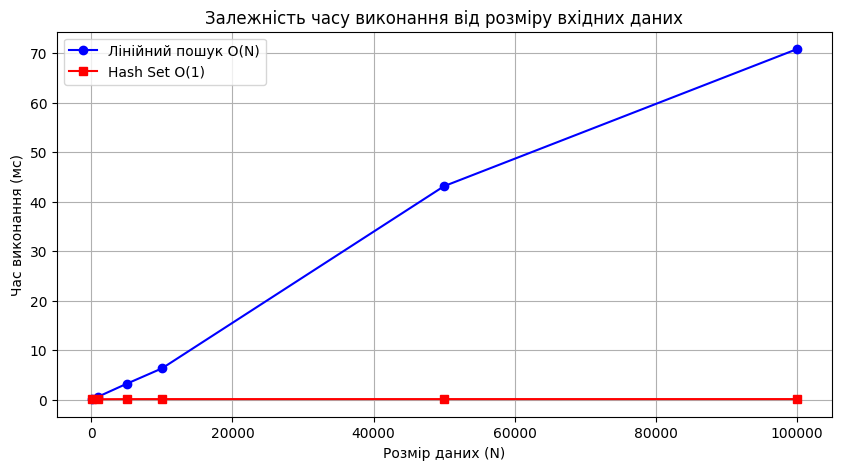

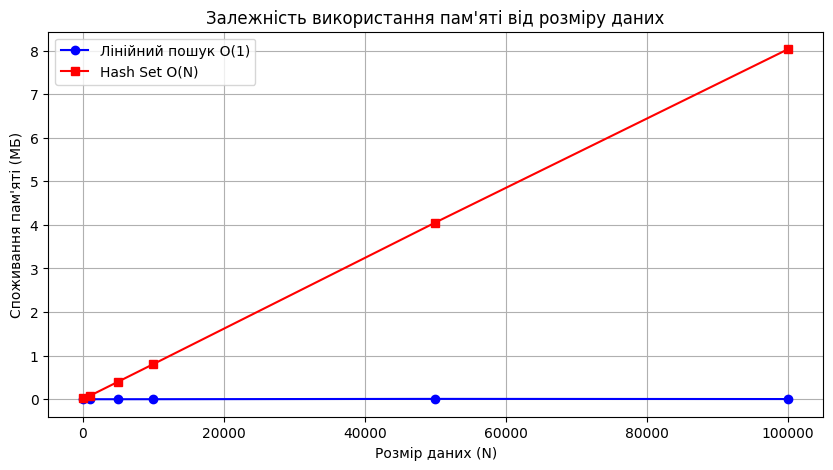

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(sizes, avg_linear_times, marker='o', color='blue', label='Лінійний пошук O(N)')
plt.plot(sizes, avg_hash_times, marker='s', color='red', label='Hash Set O(1)')
plt.title("Залежність часу виконання від розміру вхідних даних")
plt.xlabel("Розмір даних (N)")
plt.ylabel("Час виконання (мс)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(sizes, linear_mems, marker='o', color='blue', label='Лінійний пошук O(1)')
plt.plot(sizes, hash_mems, marker='s', color='red', label='Hash Set O(N)')
plt.title("Залежність використання пам'яті від розміру даних")
plt.xlabel("Розмір даних (N)")
plt.ylabel("Споживання пам'яті (МБ)")
plt.legend()
plt.grid(True)
plt.show()


#### 9. Визначення емпіричної складності

**Характер росту часу виконання**

**Лінійний пошук:** графік часу виконання утворює пряму лінію, що йде вгору зі збільшенням розміру вхідних даних ($N$). Це вказує на пряму пропорційну залежність.

**Hash Set:** графік часу виконання є горизонтальною лінією, паралельною осі абсцис. Час пошуку залишається незмінним (біля 0.1-0.2 мс) незалежно від того, шукаємо ми серед 100 чи 100 000 елементів.

**Порівняння з теоретичною оцінкою**

Для **лінійного пошуку** емпіричні результати повністю підтверджують теоретичну часову складність **$O(n)$**. Чим більше елементів, тим більше порівнянь потрібно зробити.

Для **Hash Set** емпіричні результати підтверджують теоретичну складність **$O(1)$** для операції доступу/пошуку.

**Висновок щодо емпіричної складності**

Емпірична часова складність реалізованих алгоритмів повністю збігається з їх математичними моделями. Hash Set демонструє константну емпіричну складність $O(1)$ по часу та лінійну $O(n)$ по пам'яті. Лінійний пошук навпаки: $O(n)$ по часу та $O(1)$ по пам'яті.

##### 10. Аналіз масштабованості

**Зміна продуктивності зі збільшенням розміру даних**

**Лінійний пошук:** стрімко втрачає швидкодію (час пошуку зростає з <1 мс до >70 мс при $N=100 000$). Однак споживання пам'яті залишається стабільно мінімальним.

**Hash Set:** продуктивність пошуку зовсім не падає, але споживання оперативної пам'яті зростає лінійно, сягаючи ~8 МБ для масиву зі 100 000 елементів.

**Практичні межі застосування алгоритмів**

**Лінійний пошук** доцільно застосовувати лише для дуже малих масивів, або у мікроконтролерах/вбудованих системах, де критично не вистачає оперативної пам'яті.

**Hash Set** обмежений лише обсягом вільної RAM комп'ютера. У сучасних системах межа його застосування дуже висока.

**Обґрунтування вибору алгоритму для великих наборів даних**

Для великих наборів однозначно варто обирати **Hash Set**. Витрата додаткових мегабайтів пам'яті є абсолютно мізерною ціною за прискорення пошуку в сотні й тисячі разів порівняно з лінійним підходом.

**Висновок щодо масштабованості**

Алгоритм на основі Hash Set відмінно масштабується за часом, що робить його ідеальним для високонавантажених систем. Лінійний пошук не масштабується за часом і призведе до зависання програм при великих обсягах даних.

#### 11. Висновки

**Основні результати дослідження**

У ході лабораторної роботи було успішно реалізовано та протестовано два підходи до розв'язання задачі пошуку елемента у множині: лінійний пошук та пошук на базі структури Hash Set. Експериментальні дослідження підтвердили заявлені теоретичні характеристики $O(n)$ та $O(1)$.

**Порівняння алгоритмів (переваги та недоліки)**

**Лінійний пошук:**
  - *Переваги:* максимально простий у реалізації, не потребує етапу підготовки даних, не споживає додаткової оперативної пам'яті ($O(1)$).
  - *Недоліки:* вкрай повільний на великих об'ємах даних ($O(n)$). Кожен пошук проходить масив спочатку.

**Hash Set:**
  - *Переваги:* забезпечує блискавичний пошук за $O(1)$, швидкість якого практично не залежить від кількості даних.
  - *Недоліки:* вимагає лінійного $O(n)$ обсягу оперативної пам'яті для зберігання внутрішньої хеш-таблиці; потребує часу на початкову побудову структури (операції `insert`).

**Рекомендації щодо використання**

1. Якщо пошук виконується одноразово в несортованому масиві, доцільніше використати лінійний пошук, оскільки час на побудову Hash Set буде більшим, ніж час самого пошуку.
2. Якщо пошук виконується багаторазово на одному й тому ж наборі даних, необхідно обов'язково використовувати структуру типу Hash Set. Це фундаментальна оптимізація для баз даних, систем кешування та веб-додатків.
3. У розробці реальних програмних систем краще уникати власноручної реалізації Hash Set через неефективність обробки колізій на рівні Python (списки), а використовувати високою мірою оптимізовані вбудовані колекції мови.